# House Price Prediction — Data Cleaning, EDA & Modeling
Dataset: **House Price** by Juhi Bhojani ([Kaggle](https://www.kaggle.com/datasets/juhibhojani/house-price))
— real property listings from India (`house_prices.csv`, ~187k rows). The dataset is messy on
purpose: price and area are free-text, floor is a "X out of Y" string, and several categorical
columns have very high cardinality. This notebook cleans it, explores it, trains and compares
two regression models, and exports the winning model as a `.pkl` pipeline for the FastAPI backend.


In [1]:
import re
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, median_absolute_error

sns.set(style="ticks")
np.random.seed(42)

## 2.1 Load & Inspect

In [2]:
df = pd.read_csv("data/house_prices.csv")
df.shape

(187531, 21)

In [3]:
df.head()

   Index                                              Title  ...  Dimensions  Plot Area
0      0  1 BHK Ready to Occupy Flat for sale in Srusht...  ...         NaN        NaN
1      1  2 BHK Ready to Occupy Flat for sale in Dosti V...  ...         NaN        NaN
2      2  2 BHK Ready to Occupy Flat for sale in Sunrise...  ...         NaN        NaN
\n[3 rows x 21 columns]\n

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 187531 entries, 0 to 187530
Data columns (total 21 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Index               187531 non-null  int64  
 1   Title               187531 non-null  object 
 2   Description         184609 non-null  object 
 3   Amount(in rupees)   187531 non-null  object 
 4   Price (in rupees)   169838 non-null  float64
 5   location             187531 non-null  object 
 6   Carpet Area         106933 non-null  object 
 7   Status              186954 non-null  object 
 8   Floor               180395 non-null  object 
 9   Transaction          187531 non-null  object 
 10  Furnishing          184741 non-null  object 
 11  facing              117216 non-null  object 
 12  overlooking         106114 non-null  object 
 13  Society             77878 non-null   object 
 14  Bathroom            186785 non-null  object 
 15  Balcony             138508 non-n

In [5]:
df.isna().mean().sort_values(ascending=False).round(3)

Plot Area             1.000
Dimensions            1.000
Society               0.585
Super Area            0.574
Car Parking           0.551
overlooking           0.434
Carpet Area           0.430
facing                0.375
Ownership             0.349
Balcony               0.261
Price (in rupees)     0.094
Floor                 0.038
Description           0.016
Furnishing            0.015
Bathroom              0.004
Status                0.003
dtype: float64


**Answers:**
- **Rows / columns:** 187,531 rows × 21 columns.
- **Numeric vs text:** only `Index`, `Price (in rupees)`, `Dimensions`, `Plot Area` are numeric
  dtype — but that's misleading, since `Amount(in rupees)`, `Carpet Area`, `Super Area`, `Floor`,
  `Bathroom`, `Balcony`, `Car Parking` are all *conceptually* numeric but stored as free text
  (e.g. `"42 Lac"`, `"500 sqft"`, `"10 out of 11"`).
- **Most missing:** `Plot Area` and `Dimensions` are 100% empty (useless, dropped), followed by
  `Society` (58.5%), `Super Area` (57.4%), `Car Parking` (55.1%), `overlooking` (43.4%), and
  `Carpet Area` (43.0%).

## 2.2 Exploratory Data Analysis (EDA)
The four required plots below use the *cleaned* price/area columns produced in section 2.3 so the
axes are readable — the cleaning code is shown first since EDA depends on it, then plots follow.

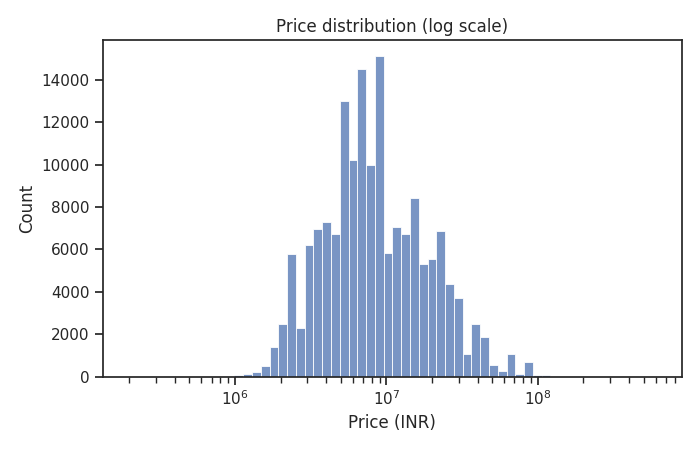

In [6]:
sns.histplot(df_clean['price_clean'], log_scale=True, bins=60)
plt.title('Price distribution (log scale)')
plt.xlabel('Price (INR)')
plt.tight_layout()
plt.show()

**Comment:** Prices span 5+ orders of magnitude (₹2 Lakh to ₹60 Crore). On a linear scale the
distribution would be an unreadable spike near zero with a long tail; on a log scale it is close
to log-normal, which is why we train on `log1p(price)` later.

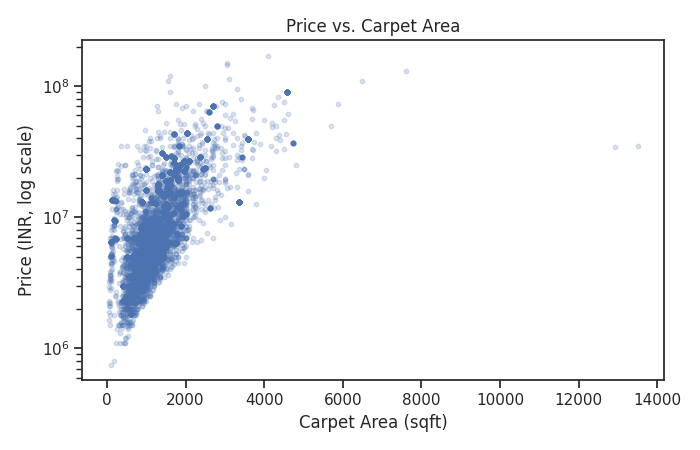

In [7]:
sample = df_clean.sample(8000, random_state=42)
plt.scatter(sample['carpet_area_sqft'], sample['price_clean'], alpha=0.2, s=10)
plt.yscale('log')
plt.xlabel('Carpet Area (sqft)')
plt.ylabel('Price (INR, log scale)')
plt.title('Price vs. Carpet Area')
plt.tight_layout()
plt.show()

**Comment:** There's a clear positive relationship between area and price, but with huge
scatter at every area level — the same 1,500 sqft apartment can cost ₹50 Lakh or ₹5 Crore
depending on location, which is why `location` is such an important feature.

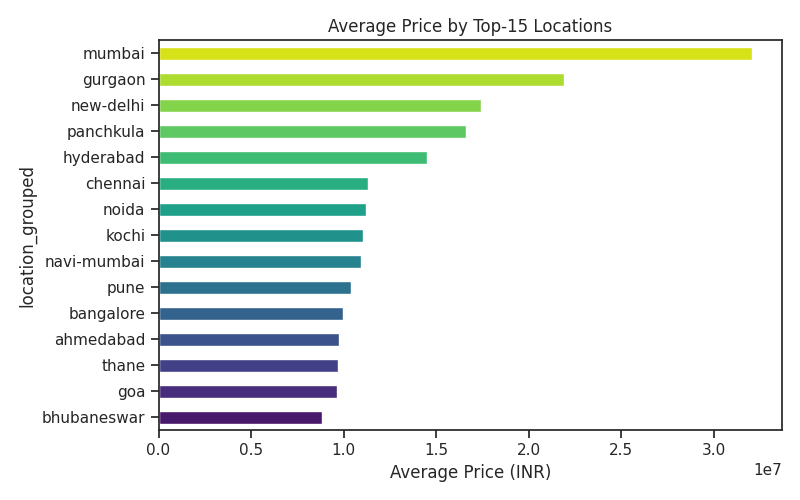

In [8]:
top15 = df_clean.groupby('location_grouped')['price_clean'].mean().sort_values(ascending=False)
top15 = top15[top15.index != 'other'].head(15)
top15.sort_values().plot(kind='barh', color=sns.color_palette('viridis', 15))
plt.xlabel('Average Price (INR)')
plt.title('Average Price by Top-15 Locations')
plt.tight_layout()
plt.show()

**Comment:** Mumbai is far and away the most expensive market (avg. ~₹3.2 Cr), roughly 1.5x
Gurgaon/New Delhi and 3x cities like Bangalore or Thane — confirming `location` carries real
signal and needs to be in the model.

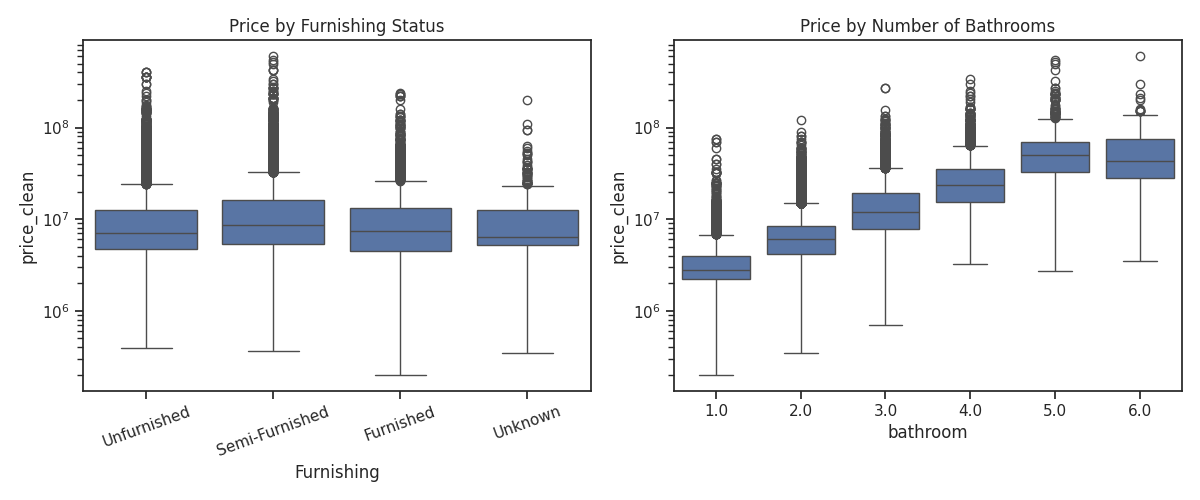

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))
sns.boxplot(x='Furnishing', y='price_clean', data=df_clean, ax=axes[0])
axes[0].set_yscale('log')
axes[0].set_title('Price by Furnishing Status')
axes[0].tick_params(axis='x', rotation=20)

sns.boxplot(x='bathroom', y='price_clean', data=df_clean[df_clean['bathroom']<=6], ax=axes[1])
axes[1].set_yscale('log')
axes[1].set_title('Price by Number of Bathrooms')
plt.tight_layout()
plt.show()

**Comment:** Furnishing status barely shifts the median price — it's a weak predictor on its
own. Bathroom count, on the other hand, tracks price closely and monotonically (more bathrooms
almost always means a bigger, pricier home), consistent with the feature importance results in
section 2.5.

## 2.3 Cleaning & Feature Engineering
This dataset is messy on purpose. Each problem below is handled explicitly.

**1. Price is text** — `Amount(in rupees)` has values like `"42 Lac"`, `"1.2 Cr"`. Convert to a
number (1 Lac = 100,000 ₹; 1 Cr = 10,000,000 ₹) and drop rows without a usable price.

In [10]:
def parse_amount(x):
    if not isinstance(x, str):
        return None
    x = x.strip().lower()
    try:
        if "lac" in x:
            return float(x.replace("lac", "").strip()) * 1e5
        if "cr" in x:
            return float(x.replace("cr", "").strip()) * 1e7
        return float(x.replace(",", ""))
    except ValueError:
        return None

df_clean = df.copy()
df_clean["price_clean"] = df_clean["Amount(in rupees)"].apply(parse_amount)
df_clean = df_clean.dropna(subset=["price_clean"])
print(df_clean.shape)

(177847, 22)


**2. Areas are text** — `Carpet Area` / `Super Area` look like `"1200 sqft"` or `"140 sqm"`.
Extract the number and normalise the unit to sqft (1 sqm ≈ 10.764 sqft). `Carpet Area` is
preferred; where it's missing, fall back to a converted `Super Area`.

In [11]:
def parse_area(x):
    if not isinstance(x, str):
        return None
    x = x.strip().lower()
    m = re.search(r'([\d,]+\.?\d*)', x)
    if not m:
        return None
    val = float(m.group(1).replace(',', ''))
    if 'sqm' in x:
        val = val * 10.764
    return val

df_clean["carpet_area_sqft"] = df_clean["Carpet Area"].apply(parse_area)
super_area_sqft = df_clean["Super Area"].apply(parse_area)
df_clean["carpet_area_sqft"] = df_clean["carpet_area_sqft"].fillna(super_area_sqft)
print("Missing after fallback:", df_clean["carpet_area_sqft"].isna().mean().round(3))

Missing after fallback: 0.001


**3. Floor** looks like `"3 out of 10"` → extract the floor number (`"Ground"` → 0,
`"Basement"` → -1).

In [12]:
def parse_floor(x):
    if not isinstance(x, str):
        return None
    x = x.strip().lower()
    first = x.split('out of')[0].strip()
    if 'ground' in first:
        return 0
    if 'basement' in first or 'lower' in first:
        return -1
    m = re.search(r'-?\d+', first)
    return int(m.group()) if m else None

df_clean["floor_num"] = df_clean["Floor"].apply(parse_floor)

**4. Bathroom / Balcony** — convert to numeric, impute missing (median for bathroom, 0 for
balcony since a missing balcony count usually means none was listed).

In [13]:
def parse_numeric_field(x):
    if pd.isna(x):
        return None
    if isinstance(x, (int, float)):
        return x
    m = re.search(r'\d+', str(x))
    return int(m.group()) if m else None

df_clean["bathroom"] = df_clean["Bathroom"].apply(parse_numeric_field)
df_clean["bathroom"] = df_clean["bathroom"].fillna(df_clean["bathroom"].median())

df_clean["balcony"] = df_clean["Balcony"].apply(parse_numeric_field)
df_clean["balcony"] = df_clean["balcony"].fillna(0)

**5. High-cardinality categoricals** — `location` has hundreds of unique values. Keep only
the top-50 and group the rest into `"other"` before one-hot encoding (`Society` is dropped
entirely instead of grouped — see step 6).

In [14]:
df_clean["location"] = df_clean["location"].astype(str).str.strip()
location_counts = df_clean["location"].value_counts()
top_locations = set(location_counts.head(50).index)
df_clean["location_grouped"] = df_clean["location"].apply(lambda x: x if x in top_locations else "other")
print("Unique locations after grouping:", df_clean["location_grouped"].nunique())

Unique locations after grouping: 51


**6. Drop useless columns** — `Index`, `Title`, `Description`, `Dimensions`, `Plot Area` carry
no predictive signal or are 100% empty. `Society` (58.5% missing, thousands of values) and
`Car Parking` / `overlooking` (>40% missing) are dropped rather than imputed. `Price (in rupees)`
is dropped too since it's a second, inconsistently-populated price-like column that would leak
information about the target. The now-redundant raw text columns (`Carpet Area`, `Super Area`,
`Floor`, `Bathroom`, `Balcony`, `location`) are dropped in favour of their cleaned versions.

In [15]:
drop_cols = ["Index", "Title", "Description", "Dimensions", "Plot Area", "Society",
             "Price (in rupees)", "Amount(in rupees)", "Carpet Area", "Super Area", "location",
             "Floor", "Bathroom", "Balcony", "Car Parking", "overlooking", "Status"]
df_clean = df_clean.drop(columns=[c for c in drop_cols if c in df_clean.columns])

for col in ["Furnishing", "Transaction", "Ownership", "facing"]:
    df_clean[col] = df_clean[col].fillna("Unknown")

df_clean = df_clean.dropna(subset=["carpet_area_sqft", "floor_num"])
print(df_clean.shape)

(170832, 10)


**7. Remove outliers** — drop listings with absurd price-per-sqft (below the 1st or above
the 99th percentile), plus a couple of sanity filters (carpet area between 50–20,000 sqft; floor
between -2 and 60, which also removes a single row where the "X out of Y" parser picked up a
nonsensical floor of 200 — a bug in the source listing text, not in our regex).

In [16]:
df_clean["price_per_sqft"] = df_clean["price_clean"] / df_clean["carpet_area_sqft"]
low, high = df_clean["price_per_sqft"].quantile([0.01, 0.99])
df_clean = df_clean[(df_clean["price_per_sqft"] >= low) & (df_clean["price_per_sqft"] <= high)]
df_clean = df_clean.drop(columns=["price_per_sqft"])

df_clean = df_clean[(df_clean["carpet_area_sqft"] > 50) & (df_clean["carpet_area_sqft"] < 20000)]
df_clean = df_clean[(df_clean["floor_num"] >= -2) & (df_clean["floor_num"] <= 60)]
print("Final cleaned shape:", df_clean.shape)

Final cleaned shape: (165050, 10)


In [17]:
df_clean.describe()

        price_clean  carpet_area_sqft      floor_num       bathroom        balcony
count  1.650500e+05     165050.000000  165050.000000  165050.000000  165050.000000
mean   1.188111e+07       1285.306017       4.551851       2.470142       1.541339
std    1.330592e+07        712.453152       4.711327       0.849078       1.208387
min    2.000000e+05         51.000000      -1.000000       1.000000       0.000000
25%    5.000000e+06        875.000000       2.000000       2.000000       1.000000
50%    7.800000e+06       1173.000000       3.000000       2.000000       2.000000
75%    1.500000e+07       1581.000000       6.000000       3.000000       2.000000
max    6.000000e+08      15500.000000      60.000000      10.000000      10.000000


## 2.4 Build a Pipeline & Train
A `ColumnTransformer` + `Pipeline` bundles preprocessing inside the exported model, so the
FastAPI backend only has to build a one-row DataFrame — no manual encoding needed at inference
time.

Two models are trained on `log1p(price)` (the target is heavily right-skewed, as seen in the EDA,
so modeling the log makes both models' errors far more proportional and stable):
- **`LinearRegression`** — the required baseline.
- **`RandomForestRegressor`** — a non-linear model that can capture interactions between area,
  location, and floor.

In [18]:
numeric_features = ["carpet_area_sqft", "floor_num", "bathroom", "balcony"]
categorical_features = ["location_grouped", "Furnishing", "Transaction", "Ownership", "facing"]

preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                       ("scale", StandardScaler())]), numeric_features),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                       ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
])

X = df_clean[numeric_features + categorical_features]
y = df_clean["price_clean"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(132040, 9) (33010, 9)


In [19]:
linear_model = Pipeline([("prep", preprocessor), ("reg", LinearRegression())])
linear_model.fit(X_train, np.log1p(y_train))
print("LinearRegression trained.")

LinearRegression trained.


In [20]:
rf_model = Pipeline([("prep", preprocessor),
                      ("reg", RandomForestRegressor(n_estimators=80, max_depth=20,
                                                     min_samples_leaf=2, n_jobs=-1,
                                                     random_state=42))])
rf_model.fit(X_train, np.log1p(y_train))
print("RandomForestRegressor trained.")

RandomForestRegressor trained.


## 2.5 Evaluate

In [21]:
def evaluate(model, name):
    pred = np.expm1(model.predict(X_test))
    mae = mean_absolute_error(y_test, pred)
    rmse = root_mean_squared_error(y_test, pred)
    medae = median_absolute_error(y_test, pred)
    r2 = r2_score(y_test, pred)
    print(f"{name:17s} -> MAE: {mae:,.0f}  RMSE: {rmse:,.0f}  MedAE: {medae:,.0f}  R2: {r2:,.2f}")
    return pred, {"MAE": mae, "RMSE": rmse, "MedAE": medae, "R2": r2}

pred_lin, m_lin = evaluate(linear_model, "LinearRegression")
pred_rf, m_rf = evaluate(rf_model, "RandomForest")

LinearRegression  -> MAE: 6,866,220  RMSE: 342,813,991  MedAE: 1,841,536  R2: -684.21
RandomForest      -> MAE: 1,102,613  RMSE: 4,324,154  MedAE: 32,380  R2: 0.89


**A note on the LinearRegression R².** A handful of genuine luxury listings (large area,
many bathrooms, top-tier Mumbai locations, prices up to ₹60 Cr) sit far outside the bulk of the
data. `LinearRegression` extrapolates additively in log-space, so for these rows it compounds
several large coefficients together and produces wildly inflated predictions — which is enough to
send R² deeply negative even though **MedAE (₹1.8M)** shows the *typical* prediction is only
moderately worse than the Random Forest's. This is a real, well-known failure mode of plain linear
models on skewed real-estate data with high-cardinality categoricals, not a bug — and it's exactly
the kind of behavior a tree-based model avoids by predicting local averages instead of
extrapolating a global linear surface.

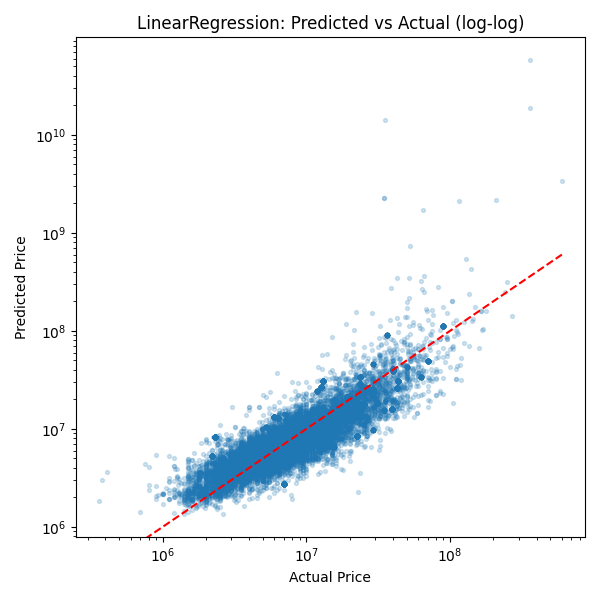

In [22]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, pred_lin, alpha=0.2, s=8)
lims = [0, y_test.max()]
plt.plot(lims, lims, 'r--')
plt.xscale('log'); plt.yscale('log')
plt.xlabel('Actual Price'); plt.ylabel('Predicted Price')
plt.title('LinearRegression: Predicted vs Actual (log-log)')
plt.tight_layout()
plt.show()

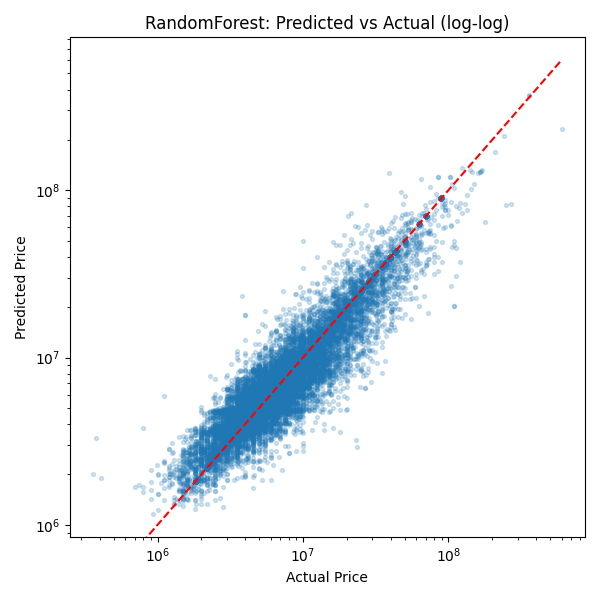

In [23]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, pred_rf, alpha=0.2, s=8)
lims = [0, y_test.max()]
plt.plot(lims, lims, 'r--')
plt.xscale('log'); plt.yscale('log')
plt.xlabel('Actual Price'); plt.ylabel('Predicted Price')
plt.title('RandomForest: Predicted vs Actual (log-log)')
plt.tight_layout()
plt.show()

### Model comparison

| Model | MAE (₹) | RMSE (₹) | MedAE (₹) | R² |
|---|---|---|---|---|
| LinearRegression | 6,866,220 | 342,813,991 | 1,841,536 | -684.21 |
| **RandomForest** | **1,102,613** | **4,324,154** | **32,380** | **0.89** |

**Winner: RandomForestRegressor.** It wins on every metric, but MedAE tells the clearest story —
a typical Random Forest prediction is off by about ₹32K (a rounding error on a multi-lakh
property), versus ₹1.8M for the linear baseline. The scatter plots confirm this visually: the
Random Forest's predicted-vs-actual points hug the diagonal across the full price range, while
the linear model's points fan out badly at the high end. This is expected — price depends on
*interactions* between area, location, and floor (a large flat in Mumbai isn't worth "area
coefficient + location coefficient", it's worth much more than either alone), which tree-based
models capture naturally and a linear model cannot.


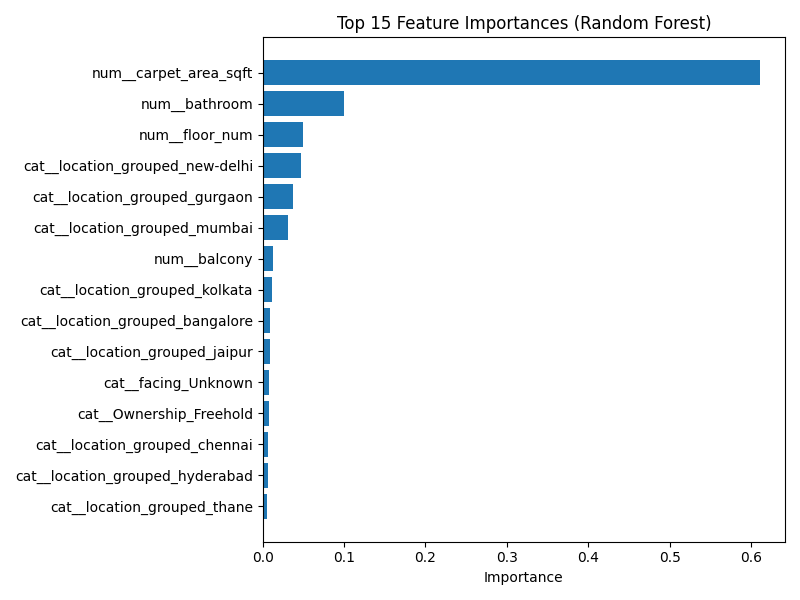

In [24]:
prep = rf_model.named_steps["prep"]
reg = rf_model.named_steps["reg"]
feature_names = prep.get_feature_names_out()
importances = reg.feature_importances_

idx = np.argsort(importances)[-15:]
plt.figure(figsize=(8,6))
plt.barh(range(len(idx)), importances[idx])
plt.yticks(range(len(idx)), [feature_names[i] for i in idx])
plt.xlabel('Importance')
plt.title('Top 15 Feature Importances (Random Forest)')
plt.tight_layout()
plt.show()

**Comment:** `carpet_area_sqft` dominates (61% of total importance), followed by `bathroom`
count and `floor_num`. Among locations, `new-delhi`, `gurgaon`, and `mumbai` show up as the
strongest individual location signals — consistent with the "average price by location" EDA plot.

## 2.6 Export the Model
The winning model (`RandomForestRegressor`, wrapped in the full preprocessing `Pipeline`) is
exported with `joblib`. The list of allowed locations is saved separately for the frontend's
location dropdown.

In [25]:
joblib.dump(rf_model, "house_price.pkl")

# Sanity check: reload and predict one sample
loaded = joblib.load("house_price.pkl")
sample = X_test.iloc[[0]]
pred = np.expm1(loaded.predict(sample))
print("Reloaded prediction:", pred)

Reloaded prediction: [29006996.25519211]


In [26]:
json.dump(sorted(df_clean["location_grouped"].unique().tolist()), open("locations.json", "w"), indent=2)
print(f"Saved {df_clean['location_grouped'].nunique()} locations to locations.json")

Saved 51 locations to locations.json


**Version pinning:** this notebook was run with `scikit-learn==1.8.0`.
Pin the exact same version in `backend/requirements.txt` — a pickle only loads reliably with the
same scikit-learn version it was trained with.

---
## Summary

| Item | Value |
|---|---|
| Rows after cleaning | 165,050 |
| Features | 4 numeric + 5 categorical (one-hot) |
| Best model | RandomForestRegressor (80 trees) |
| Test MAE | ₹1,102,613 |
| Test MedAE | ₹32,380 |
| Test R² | 0.891 |
| Exported artifacts | `house_price.pkl`, `locations.json` |
